## 1. Data splitting and challenge candidate creation


# 1. Data splitting and unseen challenge preparation

Use the prepared, cleaned CSVs. Preserve the original FNC official test file. Reserve 350 unique training article groups for the challenge, then split the remaining training groups into fit and validation. No body_id is allowed to cross partitions.

The challenge will contain 350 original headlines and 150 numeric-edit candidates (500 rows total). The 150 edits will be paired with 150 originals; 200 more originals are included without edits. Only original agree examples are used to build this small challenge. Edited labels remain pending until a person reviews them.


## 1. Imports, paths, and configuration


In [7]:
from pathlib import Path
import re
import numpy as np
import pandas as pd
from sklearn.model_selection import GroupShuffleSplit

source_dir = Path(r"B:\MTech\Codes\SEM 1\MAI\ASS\Dataset\data\processed")
new_dir = Path(r"B:\MTech\Codes\SEM 1\MAI\ASS\NEW\MTech-AIML-Project_17_Headline_Article_Consistency")
split_dir = new_dir / "data" / "splits"
challenge_dir = new_dir / "data" / "challenge"
results_dir = new_dir / "results"
for path in [split_dir, challenge_dir, results_dir]:
    path.mkdir(parents=True, exist_ok=True)

train_source_path = source_dir / "train_labeled_clean.csv"
official_test_source_path = source_dir / "official_test_labeled_clean.csv"
SEED = 42
N_CHALLENGE_ORIGINALS = 350
N_MODIFIED = 150
N_ORIGINAL_ONLY = N_CHALLENGE_ORIGINALS - N_MODIFIED


## 2. Load and validate the prepared data


In [8]:
train_all = pd.read_csv(train_source_path)
official_test = pd.read_csv(official_test_source_path)

required = {
    "headline", "body_id", "stance", "article", "article_model_input",
    "label_name", "label", "split",
}
for name, frame in [("train", train_all), ("official_test", official_test)]:
    missing = required - set(frame.columns)
    if missing:
        raise ValueError(f"{name} is missing required columns: {sorted(missing)}")
if set(train_all["split"].dropna().unique()) != {"train"}:
    raise ValueError("The prepared training file does not identify all rows as train.")
if set(official_test["split"].dropna().unique()) != {"official_test"}:
    raise ValueError("The processed test file does not identify all rows as official_test.")

stance_to_label = {"agree": 1, "discuss": 1, "disagree": 0, "unrelated": 0}
for name, frame in [("train", train_all), ("official_test", official_test)]:
    expected = frame["stance"].map(stance_to_label)
    if expected.isna().any() or not np.array_equal(expected.to_numpy(), frame["label"].astype(int).to_numpy()):
        raise ValueError(f"{name} labels do not match the established FNC mapping.")

train_ids = set(train_all["body_id"].dropna().astype(str))
test_ids = set(official_test["body_id"].dropna().astype(str))
overlap = train_ids & test_ids
if overlap:
    raise ValueError(f"Found {len(overlap)} body_id values shared by train and official test.")

print("Train rows:", len(train_all), "| unique article IDs:", train_all["body_id"].nunique())
print("Official test rows:", len(official_test), "| unique article IDs:", official_test["body_id"].nunique())
print("Train/official-test body_id overlap:", len(overlap))
display(pd.concat([
    train_all.assign(partition="train"),
    official_test.assign(partition="official_test"),
]).groupby(["partition", "label_name"]).size().rename("rows").to_frame())


Train rows: 49972 | unique article IDs: 1683
Official test rows: 25413 | unique article IDs: 904
Train/official-test body_id overlap: 0


rows
partition     label_name         
official_test consistent     6367
              inconsistent  19046
train         consistent    12587
              inconsistent  37385

## 3. Select held-out challenge articles and prepare edit candidates


## 3a. Define the numeric headline edit helper

For each candidate, find a number in the headline that also appears in the article text. Change it by one only if that changed number is absent from the article. This creates candidate edits for manual review; it does not guarantee that every edit is misleading, so the review status remains pending.


In [9]:
_NUMBER_PATTERN = re.compile(r"(?<![\w])\d[\d,]*(?![\w])")


def _number_value(token):
    """Parse a whole-number token such as 1,200; return None otherwise."""
    try:
        return int(token.replace(",", ""))
    except (TypeError, ValueError):
        return None


def make_numeric_edit(headline, article_text):
    """Return a reviewable +1 numeric headline edit, or None if unsupported."""
    if pd.isna(headline) or pd.isna(article_text):
        return None

    headline = str(headline)
    article_text = str(article_text)
    article_numbers = {
        _number_value(match.group(0))
        for match in _NUMBER_PATTERN.finditer(article_text)
    }

    for match in _NUMBER_PATTERN.finditer(headline):
        original_token = match.group(0)
        original_value = _number_value(original_token)
        if original_value is None or original_value not in article_numbers:
            continue

        changed_value = original_value + 1
        if changed_value in article_numbers:
            continue

        # Keep comma grouping if the source headline uses it.
        changed_token = f"{changed_value:,}" if "," in original_token else str(changed_value)
        edited_headline = (
            headline[:match.start()] + changed_token + headline[match.end():]
        )
        return {
            "edited_headline": edited_headline,
            "edit_type": "changed number",
            "changed_from": original_token,
            "changed_to": changed_token,
        }

    return None


In [10]:
agree_rows = train_all.loc[train_all["stance"].eq("agree")].copy()
edit_candidates = []
seen_edit_body_ids = set()

# Iterate every agree headline in shuffled order. Mark an article ID as used only
# after a valid numeric edit is found, so an uneditable first headline does not
# hide another eligible headline for the same article.
for _, row in agree_rows.sample(frac=1, random_state=SEED).iterrows():
    body_key = str(row["body_id"])
    if body_key in seen_edit_body_ids:
        continue

    edit = make_numeric_edit(row["headline"], row["article_model_input"])
    if edit is not None:
        candidate = row.to_dict()
        candidate.update(edit)
        edit_candidates.append(candidate)
        seen_edit_body_ids.add(body_key)

edit_sources = pd.DataFrame(edit_candidates)
eligible_body_count = edit_sources["body_id"].nunique()
if eligible_body_count < N_MODIFIED:
    raise ValueError(
        f"Only {eligible_body_count} unique eligible article groups support numeric edits; "
        f"{N_MODIFIED} are required."
    )
edit_sources = edit_sources.sample(n=N_MODIFIED, random_state=SEED).reset_index(drop=True)
edit_body_ids = set(edit_sources["body_id"])

original_only_candidates = (
    agree_rows.loc[~agree_rows["body_id"].isin(edit_body_ids)]
    .sample(frac=1, random_state=SEED + 1)
    .drop_duplicates("body_id")
)
if len(original_only_candidates) < N_ORIGINAL_ONLY:
    raise ValueError("Not enough distinct agree article groups for original-only challenge rows.")
original_only_sources = original_only_candidates.head(N_ORIGINAL_ONLY).reset_index(drop=True)

print("Unique eligible edit sources:", eligible_body_count)
print("Selected paired originals / edit candidates:", len(edit_sources))
print("Selected original-only examples:", len(original_only_sources))


Unique eligible edit sources: 164
Selected paired originals / edit candidates: 150
Selected original-only examples: 200
 164
Selected paired originals / edit candidates: 150
Selected original-only examples: 200


## 4. Build the review CSV and reserve challenge groups


In [11]:
challenge_rows = []

def add_original(row, pair_id, example_type):
    challenge_rows.append({
        "pair_id": pair_id,
        "example_type": example_type,
        "body_id": row["body_id"],
        "source_split": "train",
        "stance": row["stance"],
        "headline": row["headline"],
        "edited_headline": "",
        "article": row["article"],
        "article_model_input": row["article_model_input"],
        "label_name": "consistent",
        "label": 1,
        "edit_type": "original",
        "changed_from": "",
        "changed_to": "",
        "review_status": "source_agree",
        "review_notes": "Original is from FNC agree stance; confirm the pair during challenge review.",
    })

def add_edit(row, pair_id):
    challenge_rows.append({
        "pair_id": pair_id,
        "example_type": "edited",
        "body_id": row["body_id"],
        "source_split": "train",
        "stance": row["stance"],
        "headline": row["edited_headline"],
        "edited_headline": row["edited_headline"],
        "article": row["article"],
        "article_model_input": row["article_model_input"],
        "label_name": "inconsistent",
        "label": 0,
        "edit_type": row["edit_type"],
        "changed_from": row["changed_from"],
        "changed_to": row["changed_to"],
        "review_status": "pending",
        "review_notes": "Original number appears in model input and changed number does not. Manually verify before approval.",
    })

for index, row in edit_sources.iterrows():
    pair_id = f"edit_{index + 1:03d}"
    add_original(row, pair_id, "original")
    add_edit(row, pair_id)
for _, row in original_only_sources.iterrows():
    add_original(row, "", "original_only")

challenge_review = pd.DataFrame(challenge_rows)
challenge_group_ids = set(challenge_review["body_id"])
if len(challenge_review) != 500:
    raise ValueError(f"Expected 500 challenge rows, got {len(challenge_review)}.")
if len(challenge_group_ids) != 350:
    raise ValueError(f"Expected 350 distinct challenge article IDs, got {len(challenge_group_ids)}.")

challenge_review_path = challenge_dir / "challenge_headline_review.csv"
challenge_review.to_csv(challenge_review_path, index=False)
development_pool = train_all.loc[~train_all["body_id"].isin(challenge_group_ids)].copy()
if set(development_pool["body_id"]) & challenge_group_ids:
    raise AssertionError("Challenge article IDs leaked into the development pool.")


## 5. Split fit and validation by article group


In [12]:
group_splitter = GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=SEED)
fit_indices, validation_indices = next(
    group_splitter.split(
        development_pool,
        y=development_pool["label"].astype(int),
        groups=development_pool["body_id"],
    )
)
train_fit = development_pool.iloc[fit_indices].copy()
validation = development_pool.iloc[validation_indices].copy()

fit_ids = set(train_fit["body_id"])
validation_ids = set(validation["body_id"])
if fit_ids & validation_ids:
    raise AssertionError("body_id leakage between fit and validation.")
if fit_ids & challenge_group_ids or validation_ids & challenge_group_ids:
    raise AssertionError("Challenge body_id leakage into fit or validation.")
if fit_ids & test_ids or validation_ids & test_ids or challenge_group_ids & test_ids:
    raise AssertionError("Official-test body_id leakage into another partition.")
for name, frame in [("fit", train_fit), ("validation", validation), ("official_test", official_test)]:
    if set(frame["label"].astype(int).unique()) != {0, 1}:
        raise ValueError(f"{name} must contain both binary classes.")

train_fit_path = split_dir / "train_fit.csv"
validation_path = split_dir / "validation.csv"
official_test_path = split_dir / "official_test.csv"
train_fit.to_csv(train_fit_path, index=False)
validation.to_csv(validation_path, index=False)
official_test.to_csv(official_test_path, index=False)

split_summary = pd.DataFrame([
    {"partition": "fit", "rows": len(train_fit), "unique_body_ids": train_fit["body_id"].nunique()},
    {"partition": "validation", "rows": len(validation), "unique_body_ids": validation["body_id"].nunique()},
    {"partition": "official_test", "rows": len(official_test), "unique_body_ids": official_test["body_id"].nunique()},
    {"partition": "challenge", "rows": len(challenge_review), "unique_body_ids": challenge_review["body_id"].nunique()},
])
display(split_summary)
label_summary = pd.concat([
    train_fit.assign(partition="fit"),
    validation.assign(partition="validation"),
    official_test.assign(partition="official_test"),
    challenge_review.assign(partition="challenge"),
]).groupby(["partition", "label_name"]).size().rename("rows").reset_index()
display(label_summary)


,partition,rows,unique_body_ids
0,fit,31957,1066
1,validation,7670,267
2,official_test,25413,904
3,challenge,500,350


,partition,label_name,rows
0,challenge,consistent,350
1,challenge,inconsistent,150
2,fit,consistent,7710
3,fit,inconsistent,24247
4,official_test,consistent,6367
5,official_test,inconsistent,19046
6,validation,consistent,2006
7,validation,inconsistent,5664


## 6. Save split and leakage summaries


In [13]:
split_summary.to_csv(results_dir / "split_summary.csv", index=False)
label_summary.to_csv(results_dir / "split_label_distribution.csv", index=False)
pd.DataFrame([{
    "fit_validation_body_id_overlap": len(fit_ids & validation_ids),
    "fit_official_test_body_id_overlap": len(fit_ids & test_ids),
    "validation_official_test_body_id_overlap": len(validation_ids & test_ids),
    "challenge_fit_body_id_overlap": len(challenge_group_ids & fit_ids),
    "challenge_validation_body_id_overlap": len(challenge_group_ids & validation_ids),
    "challenge_official_test_body_id_overlap": len(challenge_group_ids & test_ids),
}]).to_csv(results_dir / "split_leakage_audit.csv", index=False)
print("Fit:", train_fit_path)
print("Validation:", validation_path)
print("Official test copy:", official_test_path)
print("Challenge review CSV:", challenge_review_path)
print("All source data remains unchanged.")


Fit: B:\MTech\Codes\SEM 1\MAI\ASS\NEW\data\splits\train_fit.csv
Validation: B:\MTech\Codes\SEM 1\MAI\ASS\NEW\data\splits\validation.csv
Official test copy: B:\MTech\Codes\SEM 1\MAI\ASS\NEW\data\splits\official_test.csv
Challenge review CSV: B:\MTech\Codes\SEM 1\MAI\ASS\NEW\data\challenge\challenge_headline_review.csv
All source data remains unchanged.


## 2. Model training, threshold selection, and official-test evaluation


# 2. Model training and official-test evaluation

Compare the assignment methods on the same headline/article pairs:

1. TF-IDF + cosine similarity. Fit the vocabulary and IDF only on the fit partition.
2. Pretrained sentence-transformers/all-MiniLM-L6-v2 + cosine similarity. Keep the encoder frozen; this is an embedding baseline, not fine-tuning.

Select thresholds using validation Macro-F1, lock them, then evaluate once on the preserved official test split. Do not use the official test or challenge labels to tune either method.


## 1. Imports and project paths


In [1]:
import os
os.environ["HF_HUB_DISABLE_PROGRESS_BARS"] = "1"
os.environ["HF_HUB_DISABLE_XET"] = "1"

from huggingface_hub.utils import disable_progress_bars
disable_progress_bars()

from pathlib import Path
import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sentence_transformers import SentenceTransformer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
    ConfusionMatrixDisplay, RocCurveDisplay,
)

new_dir = Path(r"B:\MTech\Codes\SEM 1\MAI\ASS\NEW\MTech-AIML-Project_17_Headline_Article_Consistency")
split_dir = new_dir / "data" / "splits"
artifacts_dir = new_dir / "artifacts"
results_dir = new_dir / "results"
artifacts_dir.mkdir(parents=True, exist_ok=True)
results_dir.mkdir(parents=True, exist_ok=True)


W1022 21:14:35.556000 7536 site-packages\torch\distributed\elastic\multiprocessing\redirects.py:29] NOTE: Redirects are currently not supported in Windows or MacOs.


## 2. Load and verify the partitions


In [2]:
train_fit = pd.read_csv(split_dir / "train_fit.csv")
validation = pd.read_csv(split_dir / "validation.csv")
official_test = pd.read_csv(split_dir / "official_test.csv")
challenge_review = pd.read_csv(new_dir / "data" / "challenge" / "challenge_headline_review.csv")

required = {"headline", "article_model_input", "body_id", "label", "label_name"}
for name, frame in [
    ("fit", train_fit), ("validation", validation),
    ("official_test", official_test), ("challenge", challenge_review),
]:
    missing = required - set(frame.columns)
    if missing:
        raise ValueError(f"{name} is missing columns: {sorted(missing)}")

fit_ids = set(train_fit["body_id"])
validation_ids = set(validation["body_id"])
test_ids = set(official_test["body_id"])
challenge_ids = set(challenge_review["body_id"])
assert fit_ids.isdisjoint(validation_ids)
assert fit_ids.isdisjoint(test_ids)
assert validation_ids.isdisjoint(test_ids)
assert fit_ids.isdisjoint(challenge_ids)
assert validation_ids.isdisjoint(challenge_ids)
assert test_ids.isdisjoint(challenge_ids)
for name, frame in [("fit", train_fit), ("validation", validation), ("official_test", official_test)]:
    assert set(frame["label"].astype(int).unique()) == {0, 1}, f"{name} lacks a class."

print("Fit rows:", len(train_fit))
print("Validation rows:", len(validation))
print("Official-test rows:", len(official_test))
print("Challenge candidate rows (not used here):", len(challenge_review))
print("All body_id overlap checks passed.")


Fit rows: 31957
Validation rows: 7670
Official-test rows: 25413
Challenge candidate rows (not used here): 500
All body_id overlap checks passed.


## 3. Fit TF-IDF on fit data and select its validation threshold


In [3]:
def choose_threshold(y_true, scores):
    """Choose threshold by validation Macro-F1; tie-break with consistent-class F1."""
    y_true = np.asarray(y_true, dtype=int)
    scores = np.asarray(scores, dtype=float)
    candidates = np.unique(np.quantile(scores, np.linspace(0, 1, 1001)))
    best = (-1.0, -1.0, 0.5)
    for threshold in candidates:
        predictions = (scores >= threshold).astype(int)
        macro = f1_score(y_true, predictions, average="macro", zero_division=0)
        consistent = f1_score(y_true, predictions, pos_label=1, zero_division=0)
        candidate = (macro, consistent, float(threshold))
        if candidate > best:
            best = candidate
    return best[2]

tfidf_vectorizer = TfidfVectorizer(
    ngram_range=(1, 2),
    min_df=2,
    sublinear_tf=True,
    strip_accents="unicode",
)
fit_corpus = (
    train_fit["headline"].astype(str).tolist()
    + train_fit["article_model_input"].astype(str).tolist()
)
tfidf_vectorizer.fit(fit_corpus)

def tfidf_similarity(frame):
    h = tfidf_vectorizer.transform(frame["headline"].astype(str))
    a = tfidf_vectorizer.transform(frame["article_model_input"].astype(str))
    return cosine_similarity(h, a).diagonal()

tfidf_validation_scores = tfidf_similarity(validation)
tfidf_threshold = choose_threshold(validation["label"], tfidf_validation_scores)
print("TF-IDF validation threshold:", tfidf_threshold)


TF-IDF validation threshold: 0.030791537785075842


## 4. Load pretrained MiniLM and select its validation threshold


In [4]:
embedding_model_name = "sentence-transformers/all-MiniLM-L6-v2"
embedding_model = SentenceTransformer(embedding_model_name)
embedding_model.max_seq_length = 128

def embedding_similarity(frame):
    headlines = embedding_model.encode(
        frame["headline"].astype(str).tolist(),
        convert_to_numpy=True,
        normalize_embeddings=True,
        batch_size=64,
        show_progress_bar=True,
    )
    articles = embedding_model.encode(
        frame["article_model_input"].astype(str).tolist(),
        convert_to_numpy=True,
        normalize_embeddings=True,
        batch_size=64,
        show_progress_bar=True,
    )
    return np.sum(headlines * articles, axis=1)

embedding_validation_scores = embedding_similarity(validation)
embedding_threshold = choose_threshold(validation["label"], embedding_validation_scores)
print("MiniLM validation threshold:", embedding_threshold)


Batches:   0%|          | 0/120 [00:00<?, ?it/s]

Batches:   0%|          | 0/120 [00:00<?, ?it/s]

MiniLM validation threshold: 0.4117567494511604


## 5. Evaluate both models on the preserved official test


In [5]:
def calculate_metrics(y_true, scores, threshold):
    y_true = np.asarray(y_true, dtype=int)
    scores = np.asarray(scores, dtype=float)
    predictions = (scores >= threshold).astype(int)
    return {
        "accuracy": accuracy_score(y_true, predictions),
        "precision": precision_score(y_true, predictions, pos_label=1, zero_division=0),
        "recall": recall_score(y_true, predictions, pos_label=1, zero_division=0),
        "macro_f1": f1_score(y_true, predictions, average="macro", zero_division=0),
        "roc_auc": roc_auc_score(y_true, scores),
        "threshold": float(threshold),
    }

tfidf_test_scores = tfidf_similarity(official_test)
minilm_test_scores = embedding_similarity(official_test)
test_metrics = pd.DataFrame([
    {"method": "TF-IDF + cosine", **calculate_metrics(official_test["label"], tfidf_test_scores, tfidf_threshold)},
    {"method": "MiniLM embeddings + cosine", **calculate_metrics(official_test["label"], minilm_test_scores, embedding_threshold)},
])
display(test_metrics.round(4))


Batches:   0%|          | 0/398 [00:00<?, ?it/s]

Batches:   0%|          | 0/398 [00:00<?, ?it/s]

,method,accuracy,precision,recall,macro_f1,roc_auc,threshold
0,TF-IDF + cosine,0.9004,0.7457,0.9144,0.8762,0.9477,0.0308
1,MiniLM embeddings + cosine,0.9571,0.8797,0.9601,0.9445,0.9848,0.4118


## 6. Confusion matrices and ROC curves


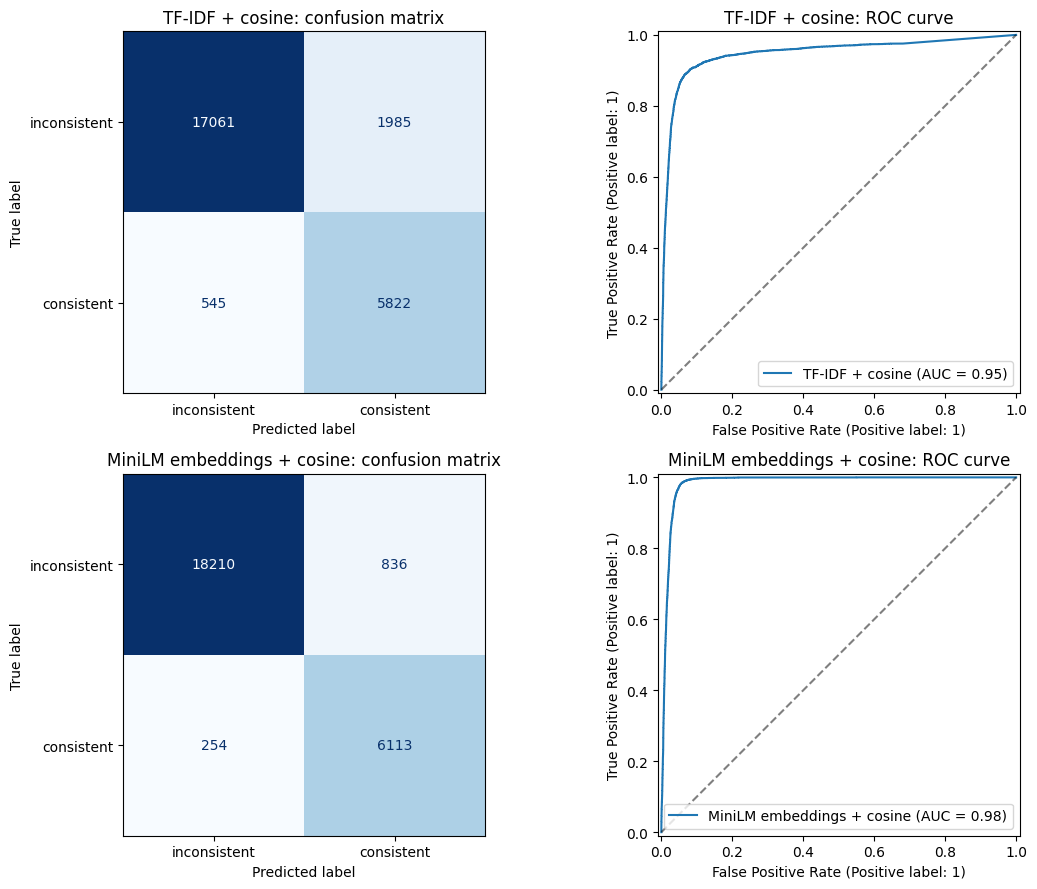

In [6]:
fig, axes = plt.subplots(2, 2, figsize=(12, 9))
for row, (name, scores, threshold) in enumerate([
    ("TF-IDF + cosine", tfidf_test_scores, tfidf_threshold),
    ("MiniLM embeddings + cosine", minilm_test_scores, embedding_threshold),
]):
    predictions = (scores >= threshold).astype(int)
    ConfusionMatrixDisplay.from_predictions(
        official_test["label"], predictions,
        display_labels=["inconsistent", "consistent"],
        cmap="Blues", colorbar=False, ax=axes[row, 0],
    )
    axes[row, 0].set_title(f"{name}: confusion matrix")
    RocCurveDisplay.from_predictions(
        official_test["label"], scores, ax=axes[row, 1], name=name
    )
    axes[row, 1].plot([0, 1], [0, 1], "k--", alpha=0.5)
    axes[row, 1].set_title(f"{name}: ROC curve")
plt.tight_layout()
plt.show()


## 7. Save thresholds, model artifacts, metrics, and predictions


In [7]:
joblib.dump(tfidf_vectorizer, artifacts_dir / "tfidf_vectorizer.joblib")
with open(results_dir / "validation_thresholds.json", "w", encoding="utf-8") as f:
    json.dump({
        "tfidf_threshold": float(tfidf_threshold),
        "embedding_threshold": float(embedding_threshold),
        "embedding_model_name": embedding_model_name,
        "embedding_max_seq_length": 128,
        "threshold_selection": "validation macro-F1; tie-break consistent-class F1",
    }, f, indent=2)

test_metrics.to_csv(results_dir / "official_test_comparison.csv", index=False)
test_predictions = official_test[
    ["headline", "article_model_input", "stance", "label_name", "label", "body_id"]
].copy()
test_predictions["tfidf_score"] = tfidf_test_scores
test_predictions["tfidf_prediction"] = (tfidf_test_scores >= tfidf_threshold).astype(int)
test_predictions["minilm_score"] = minilm_test_scores
test_predictions["minilm_prediction"] = (minilm_test_scores >= embedding_threshold).astype(int)
test_predictions.to_csv(results_dir / "official_test_predictions.csv", index=False)
print("Saved TF-IDF vectorizer, validation thresholds, official-test metrics, and predictions.")


Saved TF-IDF vectorizer, validation thresholds, official-test metrics, and predictions.


## 3. Manually reviewed modified-headline challenge


# 3. Unseen modified-headline challenge

This notebook scores challenge article groups reserved from the training side and excluded from fitting and validation. It contains 350 original agree headlines and up to 150 reviewed numeric edits. The original official test remains separate.

Review gate: inspect each edited row in data/challenge/challenge_headline_review_completed.csv against the full article. Set review_status to approved only when the edited headline is a valid inconsistent edit; otherwise set it to rejected. Do not tune thresholds here. The notebook refuses to score while any edit is pending.


## 1. Imports, paths, and load saved artifacts


In [1]:
import os
os.environ["HF_HUB_DISABLE_PROGRESS_BARS"] = "1"
os.environ["HF_HUB_DISABLE_XET"] = "1"

from huggingface_hub.utils import disable_progress_bars
disable_progress_bars()

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from sentence_transformers import SentenceTransformer
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
    ConfusionMatrixDisplay,
)

new_dir = Path(r"B:\MTech\Codes\SEM 1\MAI\ASS\NEW\MTech-AIML-Project_17_Headline_Article_Consistency")
challenge_path = new_dir / "data" / "challenge_headline_review_completed.csv"
artifacts_dir = new_dir / "artifacts"
results_dir = new_dir / "results"
results_dir.mkdir(parents=True, exist_ok=True)

challenge_review = pd.read_csv(challenge_path)
tfidf_vectorizer = joblib.load(artifacts_dir / "tfidf_vectorizer.joblib")
thresholds = pd.read_json(results_dir / "validation_thresholds.json", typ="series")
tfidf_threshold = float(thresholds["tfidf_threshold"])
minilm_threshold = float(thresholds["embedding_threshold"])
embedding_model = SentenceTransformer(str(thresholds["embedding_model_name"]))
embedding_model.max_seq_length = int(thresholds["embedding_max_seq_length"])


W1022 21:59:32.368000 13820 site-packages\torch\distributed\elastic\multiprocessing\redirects.py:29] NOTE: Redirects are currently not supported in Windows or MacOs.


## 2. Enforce human review before scoring


In [2]:
edited_rows = challenge_review.loc[challenge_review["example_type"].eq("edited")].copy()
allowed_statuses = {"approved", "rejected"}
unreviewed = edited_rows.loc[~edited_rows["review_status"].isin(allowed_statuses)]
if len(unreviewed):
    raise ValueError(
        f"{len(unreviewed)} edit candidates are still pending. Review them in the CSV "
        "and set each review_status to approved or rejected before scoring."
    )

approved_edits = edited_rows.loc[edited_rows["review_status"].eq("approved")].copy()
if approved_edits.empty:
    raise ValueError("No edited headlines were approved.")
if not (approved_edits["label"].astype(int) == 0).all():
    raise ValueError("Approved edited headlines must have label 0 (inconsistent).")

original_rows = challenge_review.loc[
    challenge_review["example_type"].isin(["original", "original_only"])
].copy()
if not (original_rows["label"].astype(int) == 1).all():
    raise ValueError("Original agree headlines must have label 1 (consistent).")

challenge = pd.concat([original_rows, approved_edits], ignore_index=True)
print("Scored rows:", len(challenge))
print("Original consistent rows:", len(original_rows))
print("Approved inconsistent edits:", len(approved_edits))
print("Approved paired edits:", approved_edits["pair_id"].nunique())
display(challenge.groupby(["example_type", "label_name"]).size().rename("count").to_frame())


Scored rows: 482
Original consistent rows: 350
Approved inconsistent edits: 132
Approved paired edits: 132


,,count
example_type,label_name,
edited,inconsistent,132
original,consistent,150
original_only,consistent,200


## 3. Score with the two required cosine-similarity methods


In [3]:
def tfidf_similarity(headlines, articles):
    h = tfidf_vectorizer.transform(pd.Series(headlines).astype(str))
    a = tfidf_vectorizer.transform(pd.Series(articles).astype(str))
    return cosine_similarity(h, a).diagonal()

def minilm_similarity(headlines, articles):
    h = embedding_model.encode(
        pd.Series(headlines).astype(str).tolist(),
        convert_to_numpy=True, normalize_embeddings=True,
        batch_size=64, show_progress_bar=True,
    )
    a = embedding_model.encode(
        pd.Series(articles).astype(str).tolist(),
        convert_to_numpy=True, normalize_embeddings=True,
        batch_size=64, show_progress_bar=True,
    )
    return np.sum(h * a, axis=1)

challenge["tfidf_score"] = tfidf_similarity(
    challenge["headline"], challenge["article_model_input"]
)
challenge["tfidf_prediction"] = (challenge["tfidf_score"] >= tfidf_threshold).astype(int)
challenge["minilm_score"] = minilm_similarity(
    challenge["headline"], challenge["article_model_input"]
)
challenge["minilm_prediction"] = (challenge["minilm_score"] >= minilm_threshold).astype(int)


Batches:   0%|          | 0/8 [00:00<?, ?it/s]

Batches:   0%|          | 0/8 [00:00<?, ?it/s]

## 4. Calculate assignment metrics and paired-edit success


In [4]:
def metrics(y_true, scores, threshold):
    y_true = np.asarray(y_true, dtype=int)
    scores = np.asarray(scores, dtype=float)
    predictions = (scores >= threshold).astype(int)
    return {
        "accuracy": accuracy_score(y_true, predictions),
        "precision": precision_score(y_true, predictions, pos_label=1, zero_division=0),
        "recall": recall_score(y_true, predictions, pos_label=1, zero_division=0),
        "macro_f1": f1_score(y_true, predictions, average="macro", zero_division=0),
        "roc_auc": roc_auc_score(y_true, scores),
        "threshold": float(threshold),
    }

results = []
for method, score_col, prediction_col, threshold in [
    ("TF-IDF + cosine", "tfidf_score", "tfidf_prediction", tfidf_threshold),
    ("MiniLM embeddings + cosine", "minilm_score", "minilm_prediction", minilm_threshold),
]:
    pred = challenge[prediction_col].to_numpy()
    original_mask = challenge["example_type"].isin(["original", "original_only"]).to_numpy()
    edited_mask = challenge["example_type"].eq("edited").to_numpy()
    approved_pair_ids = set(approved_edits["pair_id"])
    paired_rows = challenge.loc[challenge["pair_id"].isin(approved_pair_ids)]
    paired = paired_rows.pivot(
        index="pair_id", columns="example_type", values=prediction_col
    )
    results.append({
        "method": method,
        **metrics(challenge["label"], challenge[score_col], threshold),
        "original_acceptance_rate": float((pred[original_mask] == 1).mean()),
        "edited_rejection_rate": float((pred[edited_mask] == 0).mean()),
        "paired_flip_success": float(((paired["original"] == 1) & (paired["edited"] == 0)).mean()) if len(paired) else np.nan,
    })

challenge_metrics = pd.DataFrame(results)
display(challenge_metrics.round(4))



,method,accuracy,precision,recall,macro_f1,roc_auc,threshold,original_acceptance_rate,edited_rejection_rate,paired_flip_success
0,TF-IDF + cosine,0.7137,0.7265,0.9714,0.4430,0.4327,0.0308,0.9714,0.0303,0.0227
1,MiniLM embeddings + cosine,0.7054,0.7291,0.9457,0.4679,0.4773,0.4118,0.9457,0.0682,0.0152


## 5. Plot confusion matrices and review missed edits


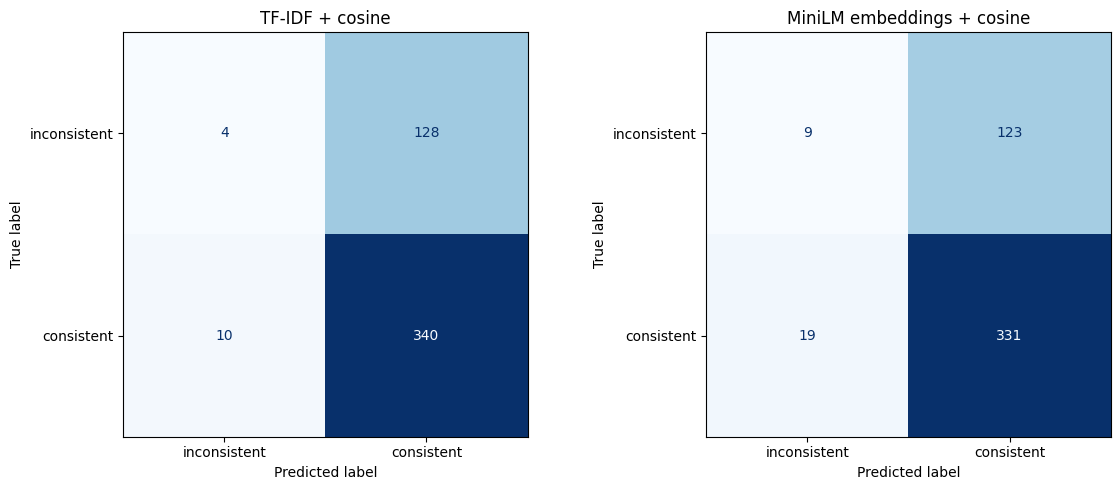

Edited headlines predicted consistent by at least one model: 129


,pair_id,headline,changed_from,changed_to,review_notes,tfidf_score,tfidf_prediction,minilm_score,minilm_prediction
350,edit_001,"Michael Phelps' self-proclaimed 'girlfriend', ...","41,",42,"Original supported: article states 'to Phelps,...",0.160818,1,0.787710,1
351,edit_002,The iPhone 7 'Hairgate' Is Not a Thing,6,7,Article attributes 'Hairgate' to the iPhone 6 ...,0.028689,0,0.512025,1
352,edit_003,"It was me! Student, 20 reveals SHE was the Tel...","19,",20,Original supported: article states 'revaled he...,0.130816,1,0.445772,1
353,edit_004,Ottawa gunman identified as 33-year-old Michae...,32,33,Original supported: article states 'the War Me...,0.173788,1,0.592389,1
354,edit_005,Axl Rose Found Dead of Sh*tty Hoax Website at ...,52,53,Original supported: article states 'Axl Rose w...,0.167328,1,0.751820,1
355,edit_006,Cheeky vandals paint giant penis on bonnet of ...,1,2,Article states 'The owner of a £1.5 million Bu...,0.293188,1,0.638556,1
356,edit_007,We took a look at the photo said to show the b...,2013,2014,Original supported: article states 'picture of...,0.236698,1,0.710992,1
357,edit_009,"Comfort eating? Chinese woman, 27 spends an en...","26,",27,Original supported: article states 'she ‘neede...,0.340881,1,0.592012,1
358,edit_010,"Islamic State, in video titled ""A Message to A...",2012,2013,Original supported: article states 'freelance ...,0.163331,1,0.744028,1
359,edit_011,Planetary Alignment Decrease Gravity Hoax on J...,2015,2016,Article states the hoax claims a planetary ali...,0.395055,1,0.844621,1


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, method, column in [
    (axes[0], "TF-IDF + cosine", "tfidf_prediction"),
    (axes[1], "MiniLM embeddings + cosine", "minilm_prediction"),
]:
    ConfusionMatrixDisplay.from_predictions(
        challenge["label"], challenge[column],
        display_labels=["inconsistent", "consistent"],
        cmap="Blues", colorbar=False, ax=ax,
    )
    ax.set_title(method)
plt.tight_layout()
plt.show()

missed_edits = challenge.loc[
    challenge["example_type"].eq("edited")
    & ((challenge["tfidf_prediction"] == 1) | (challenge["minilm_prediction"] == 1)),
    ["pair_id", "headline", "changed_from", "changed_to", "review_notes",
     "tfidf_score", "tfidf_prediction", "minilm_score", "minilm_prediction"],
]
print("Edited headlines predicted consistent by at least one model:", len(missed_edits))
display(missed_edits.head(25))


## 6. Save challenge metrics and per-example predictions


In [6]:
challenge_metrics.to_csv(results_dir / "unseen_modified_challenge_metrics.csv", index=False)
challenge.to_csv(results_dir / "unseen_modified_challenge_predictions.csv", index=False)
print("Saved challenge metrics and predictions under:", results_dir)


Saved challenge metrics and predictions under: B:\MTech\Codes\SEM 1\MAI\ASS\NEW\results
